# Pneumonia baseline reconstruction with online image training

Samarth Shekhar 230042, Meghavi Rao 230044, Rachit Kumar 230128, Harshal Nerpagar 230076.

Base paper: [Chouhan et al. 2020](https://doi.org/10.3390/app10020559). Five ImageNet CNNs, paper trainable boundaries, majority voting. This is our third experiment, with five fixed epochs on all 5,232 training records, fresh augmentation, FP32 full-image forwards and updating BatchNorm running statistics while retaining frozen early weights. Three models trained on the Mac and two in the isolated CPU VPS. The original 624-record test set stays unchanged.

Training ran in the CLI jobs. This notebook executes analysis and independent verification of actual saved artifacts, not simulated training outputs. Five epochs is shorter than the paper50-200 schedules, and author settings remain partly unspecified. No test-driven checkpoint or threshold choice. Crop plus ViT is still an unimplemented M3 proposal.

In [1]:
from pathlib import Path
import sys,json,numpy as np,pandas as pd
ROOT=Path.cwd()
if ROOT.name=='output':ROOT=ROOT.parent
if (ROOT/'m2_m3').is_dir():ROOT=ROOT/'m2_m3'
assert (ROOT/'experiments/paper_online5').is_dir()
EXP=ROOT/'experiments/paper_online5';OUT=EXP/'results'
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(EXP))
from engine import MODEL_NAMES,evaluate,CONFIG
summary=json.loads((OUT/'summary.json').read_text())
receipt=json.loads((OUT/'independent_verification.json').read_text())
assert receipt['verified'] and summary['test_evaluated']
print(json.dumps(CONFIG,indent=2))


{
  "seed": 42,
  "epochs": 5,
  "batch_size": 16,
  "device": "cpu",
  "threads": 2,
  "training_records": 5232,
  "test_records": 624,
  "class_mapping": {
    "normal": 0,
    "pneumonia": 1
  },
  "frozen_weights": "P7 Figures4-8 boundaries",
  "batchnorm": "All running statistics update in train mode; affine gradients follow stated frozen/trainable boundaries. Author statistics policy unspecified.",
  "augmentation": "Fresh per-example horizontal flip0.5, random resized crop scale0.8-1.0 ratio0.75-1.3333, brightness/contrast0.15, grayscale-shared Gaussian pixel noise std0.01. All training examples augmented; no fixed-view caches.",
  "normalization": {
    "mean": [
      0.485,
      0.456,
      0.406
    ],
    "std": [
      0.229,
      0.224,
      0.225
    ]
  },
  "optimizer": {
    "name": "Adam",
    "initial_lr": 0.001,
    "betas": [
      0.9,
      0.999
    ],
    "eps": 1e-08,
    "weight_decay": 0
  },
  "lr": "Non-AlexNet: halve every3 epochs. AlexNet: first200 

P7 ONLINE FIVE EPOCH RECONSTRUCTION
Locked before this run on 6 October 2026. No guaranteed score improvement.

WHAT MATCHES RECOVERABLE PAPER DETAILS
Use train plus original validation: 5232 records, 1349 normal and3883 pneumonia.
Keep the original624 test records,234 normal and390 pneumonia. Retain original
record multiplicity for comparability. No exact source hash crosses partitions.
Keep the initial224x224 RGB resize, five ImageNet backbones and trainable boundaries
from Figures4-8. AlexNet classifier9216->512->2. Adam/cross entropy. Initial LR.001,
halved every3 epochs except AlexNet's stated200 optimizer steps then.00001.
Final class comes from three-of-five votes, component threshold.5.
AUC uses mean pneumonia probability; the author's executable score definition is
not supplied. No class weighting, crop, ViT, test-time augmentation or test tuning.

CORRECTIONS RELATIVE TO OUR PREVIOUS RESOURCE APPROXIMATION
No frozen feature cache and no float16 activation conversion. Forward actual image
pixels in FP32. Sample fresh augmentation per example on every epoch, not one
fixed clean/augmented view for an entire epoch. Frozen parameters receive no
gradients. Ordinary model.train() updates BatchNorm running statistics while
affine gradients follow the paper's frozen/trainable weight boundaries.
Disable unused auxiliary classifiers. Run one model at a time with two CPU
threads, batch16, worker0 and the existing memory/disk guards.

HONEST LIMITS THAT CANNOT BE ELIMINATED BY CLAIMING PERFECTION
We precommit to FIVE epochs and final epoch-five weights to meet the deadline,
not the paper's50-200 epochs. All5232 records train, so this paper-comparison run
has no independent validation checkpoint selection. Exact author batch size,
normalization, noise/crop/intensity settings, BatchNorm policy, weight revision,
dropout details and split file manifest are unavailable. AlexNet's prose says200
iterations while its table says200 epochs; this run interprets the LR switch as
200 optimizer steps. These assumptions are specified in CONFIG.json, not silently
presented as exact author choices. The benchmark test was inspected earlier and
cannot be called blind. Filename patient identifiers are unverified proxies.

PRETRAINING AND EVALUATION SAFETY
Before training: scan all image files, labels and counts; verify trainable parameter
names; test finite logits/loss/gradients, frozen weights unchanged, trainable weights
updated, BatchNorm-statistics behavior, disabled auxiliary branches, transform
randomness/repeatability, LR boundaries, arbitrary prediction batches and sampling.
Preflight models are discarded. Actual training starts again from ImageNet.
Save full model/optimizer/RNG/sampler state at each epoch for safe resumption.
Abort on nonfinite loss/gradients or resource bounds. Do not mask failures.
After ALL final checkpoints exist: evaluate each test image exactly once, calculate
majority votes and all class metrics, then independently reload full checkpoints
and rerun complete test forwards. Recalculate scores from per-image predictions.
No hyperparameter, threshold or checkpoint selection based on test performance.

This remains a bounded, explicitly documented reproduction. We cannot guarantee
zero unknown edge cases or equivalence to unpublished author code. A lower score
must be reported, not hidden or used to justify test-driven retries.


## Full executable implementation

The attached engine.py, preflight.py and run.py contain the complete model assembly, image transforms and training loop. Keep RUN_TRAINING=False for saved-results inspection. Reproduction deliberately requires images and official weights, resource checks and a long CPU run. Previously completed checkpoints are retained; use a separate experiment directory for a genuinely new run.

In [2]:
from IPython.display import Code,display
for filename in ['engine.py','preflight.py','run.py']:
    print(filename)
    display(Code((EXP/filename).read_text(),language='python'))
RUN_TRAINING=False
if RUN_TRAINING:
    import subprocess
    subprocess.run([sys.executable,str(EXP/'preflight.py')],check=True)
    subprocess.run([sys.executable,str(EXP/'run.py')],check=True)


engine.py


"""P7 full-image, full-training-partition, online FP32 reconstruction helpers."""
import os
os.environ.setdefault('OMP_NUM_THREADS','2')
os.environ.setdefault('OPENBLAS_NUM_THREADS','2')
os.environ.setdefault('VECLIB_MAXIMUM_THREADS','2')
import sys,json,random,hashlib
from pathlib import Path
HERE=Path(__file__).resolve().parent;ROOT=HERE.parents[1]
sys.path.insert(0,str(ROOT))
import numpy as np,torch,psutil
from PIL import Image
from torchvision import transforms
from baseline import build_model,MODEL_NAMES,guard,evaluate
SEED=42;EPOCHS=5;BATCH=16
CONFIG=dict(seed=SEED,epochs=EPOCHS,batch_size=BATCH,device='cpu',threads=2,
 training_records=5232,test_records=624,class_mapping={'normal':0,'pneumonia':1},
 frozen_weights='P7 Figures4-8 boundaries',batchnorm='All running statistics update in train mode; affine gradients follow stated frozen/trainable boundaries. Author statistics policy unspecified.',
 augmentation='Fresh per-example horizontal flip0.5, random resized crop scale0.8-1.0 ratio0.75-1.3333, brightness/contrast0.15, grayscale-shared Gaussian pixel noise std0.01. All training examples augmented; no fixed-view caches.',
 normalization={'mean':[.485,.456,.406],'std':[.229,.224,.225]},
 optimizer={'name':'Adam','initial_lr':.001,'betas':[.9,.999],'eps':1e-8,'weight_decay':0},
 lr='Non-AlexNet: halve every3 epochs. AlexNet: first200 optimizer steps0.001 then0.00001.',
 checkpoint='Fixed final epoch5 per model, no selection using any test score',
 precision='FP32 complete image forwards and trainable layers, no activation quantization',
 auxiliary_heads='GoogLeNet and Inception unused auxiliary classifiers disabled',
 test_history='Original benchmark was inspected in earlier experiments; not a blind external holdout',
 known_departures=['Five epochs instead of paper50-200','Author batch size, transform parameters, noise distribution, normalization, BatchNorm-statistics and exact pretrained revision not recovered','AlexNet200-iteration prose versus200-epoch table ambiguity; use literal optimizer steps','Initial224 RGB bilinear cache follows stated resize, but author interpolation/file manifest unverified'])
CONFIG_HASH=hashlib.sha256(json.dumps(CONFIG,sort_keys=True).encode()).hexdigest()
class SharedGrayNoise:
    def __call__(self,x):
        # Keep a grayscale radiograph grayscale before channel normalization.
        return (x+torch.randn(1,x.shape[1],x.shape[2],dtype=x.dtype)*.01).clamp(0,1)
def image_transform(training=False):
    ops=[]
    if training:ops.extend([transforms.RandomHorizontalFlip(.5),transforms.RandomResizedCrop(224,scale=(.8,1),ratio=(.75,4/3)),transforms.ColorJitter(brightness=.15,contrast=.15)])
    ops.append(transforms.ToTensor())
    if training:ops.append(SharedGrayNoise())
    ops.append(transforms.Normalize(CONFIG['normalization']['mean'],CONFIG['normalization']['std']))
    return transforms.Compose(ops)
class Images(torch.utils.data.Dataset):
    def __init__(self,rows,training=False):self.rows=rows;self.transform=image_transform(training)
    def __len__(self):return len(self.rows)
    def __getitem__(self,i):
        r=self.rows[i]
        with Image.open(ROOT/r['path']) as im:
            if im.size!=(224,224):raise ValueError(f'Unexpected resized input dimensions: {r["path"]}')
            x=self.transform(im.convert('RGB'))
        return x,int(r['label']),i
def records():
    rs=json.loads((ROOT/'data/manifest.json').read_text())
    train=[r for r in rs if r['split']!='test'];test=[r for r in rs if r['split']=='test']
    assert len(train)==5232 and len(test)==624
    assert [sum(r['label']==c for r in train) for c in [0,1]]==[1349,3883]
    assert [sum(r['label']==c for r in test) for c in [0,1]]==[234,390]
    assert not {r['sha256'] for r in train}&{r['sha256'] for r in test}
    return train,test
def model(name):
    prefix,tail,boundary=build_model(name);prefix.handle.remove();m=prefix.model
    if name=='resnet18':m.fc=tail[3]
    elif name=='densenet121':m.classifier=tail.fc

preflight.py


"""Fail-fast checks before the bounded online reconstruction starts."""
import json,time,gc,hashlib,sys
from pathlib import Path
import engine as e
import numpy as np,torch,psutil
from PIL import Image
from torch import nn
def main():
    train,test=e.records();seen={};labels={}
    for r in train+test:
        assert r['label'] in [0,1] and (e.ROOT/r['path']).is_file()
        assert labels.setdefault(r['sha256'],r['label'])==r['label']
        if r['path'] not in seen:
            with Image.open(e.ROOT/r['path']) as im:
                im.verify()
            with Image.open(e.ROOT/r['path']) as im:
                a=np.array(im.convert('RGB'));assert a.shape==(224,224,3) and np.isfinite(a).all()
            seen[r['path']]=True
    print('ALL_IMAGES_DECODED',len(seen),'unique paths',flush=True)
    chosen=[next(r for r in train if r['label']==c) for c in [0,1]]*8
    e.seed_all();ds=e.Images(chosen,True);a=ds[0][0];b=ds[0][0];assert not torch.equal(a,b)
    e.seed_all();assert torch.equal(a,ds[0][0])
    clean=e.Images(chosen,False);assert torch.equal(clean[0][0],clean[0][0])
    assert e.lr_for('resnet18',2,999)==.001 and e.lr_for('resnet18',3,999)==.0005
    assert e.lr_for('alexnet',0,199)==.001 and e.lr_for('alexnet',0,200)==.00001
    tests=[]
    for name in e.MODEL_NAMES:
        e.guard();e.seed_all();m,boundary=e.model(name);m.train();e.seed_all()
        x=torch.stack([ds[i][0] for i in range(16)]);y=torch.tensor([r['label'] for r in chosen])
        frozen=next((n,p) for n,p in m.named_parameters() if not p.requires_grad)
        trainable=[(n,p) for n,p in m.named_parameters() if p.requires_grad]
        frozen_before=frozen[1].detach().clone();last_before=trainable[-2][1].detach().clone()
        bns=[b for b in m.modules() if isinstance(b,nn.modules.batchnorm._BatchNorm)]
        counters=[int(b.num_batches_tracked) for b in bns]
        opt=torch.optim.Adam([p for n,p in trainable],lr=.001);start=time.perf_counter()
        z=m(x);assert z.shape==(16,2) and torch.isfinite(z).all()
        loss=nn.functional.cross_entropy(z,y);assert torch.isfinite(loss)
        loss.backward()
        assert all(p.grad is None for p in m.parameters() if not p.requires_grad)
        assert all(p.grad is not None and torch.isfinite(p.grad).all() for n,p in trainable)
        opt.step()
        assert torch.equal(frozen_before,frozen[1])
        assert not torch.equal(last_before,trainable[-2][1])
        assert all(int(b.num_batches_tracked)==n+1 for b,n in zip(bns,counters))
        seconds=time.perf_counter()-start;rss=psutil.Process().memory_info().rss/1024**2;e.guard()
        m.eval()
        with torch.inference_mode():
            one=m(x[:1]);assert one.shape==(1,2) and torch.isfinite(one).all()
        # Check exact state serialization/reload without writing a checkpoint.
        state={k:v.detach().clone() for k,v in m.state_dict().items()};m.load_state_dict(state)
        with torch.inference_mode():assert torch.allclose(one,m(x[:1]),atol=1e-7,rtol=1e-7)
        sampler=torch.Generator().manual_seed(e.SEED)
        indexes=[]
        for bx,by,ix in e.loader(chosen,True,sampler):indexes.extend(ix.tolist())
        assert sorted(indexes)==list(range(len(chosen)))
        tests.append(dict(model=name,boundary=boundary,trainable_parameter_count=sum(p.numel() for n,p in trainable),batch16_forward_backward_seconds=seconds,rss_mb=rss,finite_loss=float(loss.detach()),frozen_weights_unchanged=True,trainable_weights_updated=True,all_trainable_gradients_present=True,batchnorm_counters_updated=len(bns),single_image_eval_and_state_reload=True))
        print('MODEL_PREFLIGHT_PASS',tests[-1],flush=True)
        del m,opt,x,y,z,loss,state,one,trainable,frozen,frozen_before,last_before,bns;gc.collect()
    for w in json.loads((e.ROOT/'sources/pretrained_weight_checksums.json').read_text()):
        f=Path(torch.hub.get_dir())/'checkpoints'/w['file']
        assert f.exists() and hashlib.sha256(f.read_bytes()).hexdigest()==w['sha25

run.py


"""Five epochs on all5232 paper-training images with online augmentation."""
import time,json,gc,hashlib,csv,random,platform,argparse
from pathlib import Path
import engine as e
import numpy as np,torch,psutil
from torch import nn
OUT=e.HERE/'results';OUT.mkdir(exist_ok=True)
def status(phase,model=None,epoch=None,batch=None,**extra):
    e.atomic_json(e.HERE/'STATUS.json',dict(phase=phase,current_model=model,current_epoch=epoch,current_batch=batch,updated=time.strftime('%Y-%m-%d %H:%M:%S'),epochs_per_model=e.EPOCHS,completed_models=[n for n in e.MODEL_NAMES if (OUT/f'{n}_complete.json').exists()],**extra))
def train_model(name,rows):
    if (OUT/f'{name}_complete.json').exists():
        done=json.loads((OUT/f'{name}_complete.json').read_text());assert done['config_hash']==e.CONFIG_HASH
        assert (OUT/f'{name}_final.pt').exists();return
    e.seed_all();m,boundary=e.model(name);e.seed_all()
    generator=torch.Generator().manual_seed(e.SEED)
    opt=torch.optim.Adam([p for p in m.parameters() if p.requires_grad],lr=.001,betas=(.9,.999),eps=1e-8,weight_decay=0)
    history=[];steps=0;begin=0;resume=OUT/f'{name}_resume.pt';start=time.time()
    if resume.exists():
        state=torch.load(resume,map_location='cpu',weights_only=False)
        assert state['config_hash']==e.CONFIG_HASH
        m.load_state_dict(state['model']);opt.load_state_dict(state['optimizer']);begin=state['completed_epochs'];steps=state['steps'];history=state['history']
        torch.set_rng_state(state['torch_rng']);generator.set_state(state['sampler_rng']);np.random.set_state(state['numpy_rng']);random.setstate(state['python_rng'])
        del state;gc.collect();print('RESUME',name,'after',begin,'epochs',flush=True)
    for epoch in range(begin,e.EPOCHS):
        m.train();loader=e.loader(rows,True,generator);loss_sum=0.;seen=np.zeros(len(rows),dtype=np.int16);epoch_start=time.time();correct=0;first_hash=None
        for batch,(x,y,indexes) in enumerate(loader):
            e.guard();assert torch.equal(y,torch.tensor([rows[i]['label'] for i in indexes.tolist()]))
            assert torch.isfinite(x).all() and x.dtype==torch.float32
            lr=e.lr_for(name,epoch,steps)
            for g in opt.param_groups:g['lr']=lr
            opt.zero_grad(set_to_none=True);logits=m(x);assert logits.shape==(len(x),2) and torch.isfinite(logits).all()
            loss=nn.functional.cross_entropy(logits,y);assert torch.isfinite(loss),'Nonfinite training loss'
            loss.backward()
            assert all(p.grad is None for p in m.parameters() if not p.requires_grad)
            assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in m.parameters() if p.requires_grad)
            opt.step();steps+=1;loss_sum+=float(loss.detach())*len(y);correct+=int((logits.argmax(1)==y).sum());seen[indexes.numpy()]+=1
            if first_hash is None:first_hash=hashlib.sha256(x.numpy().tobytes()).hexdigest()
            if batch%32==0:
                status('training',name,epoch+1,batch+1,steps=steps,elapsed_seconds=time.time()-start,rss_mb=round(psutil.Process().memory_info().rss/1024**2))
                print('TRAIN',name,'epoch',epoch+1,'batch',batch+1,'/',len(loader),'loss',round(float(loss.detach()),5),flush=True)
            time.sleep(.008)
        assert (seen==1).all(), 'Every training record must occur exactly once per epoch'
        h=dict(epoch=epoch+1,training_records=int(seen.sum()),optimizer_steps=steps,training_loss=loss_sum/len(rows),training_accuracy_augmented=correct/len(rows),last_learning_rate=opt.param_groups[0]['lr'],first_augmented_batch_sha256=first_hash,seconds=time.time()-epoch_start)
        history.append(h)
        assert len({a['first_augmented_batch_sha256'] for a in history})==len(history)
        state=dict(config_hash=e.CONFIG_HASH,model=m.state_dict(),optimizer=opt.state_dict(),completed_epochs=epoch+1,steps=steps,history=history,torch_rng=torch.get_rng_state(),sampler_rng=generator.get_state(),numpy_rng=np.random.get_st

## Independent checkpoint verification

The supplied receipt records the completed CLI reload verification of every full checkpoint on all624 images, including actual epochs/record counts and BatchNorm counters. Below, this notebook independently recalculates metrics from saved per-image scores. Set RECHECK_WEIGHTS=True to deliberately repeat all full-image forwards inside the notebook. A compact distribution omits large checkpoints/images, so full learned-weight rechecking requires reproduction.

In [3]:
RECHECK_WEIGHTS=False  # CLI already completed the full-checkpoint forward verification
weights_present=all((OUT/f'{n}_final.pt').exists() for n in MODEL_NAMES)
if RECHECK_WEIGHTS and weights_present:
    from verify import verify
    verified=verify()
    assert verified['verified']
else:
    print('Completed CLI full-checkpoint verification receipt:',receipt['verified'])
    print('Notebook independently checks saved per-image metrics below. Full forward recheck remains optional.')
manifest=json.loads((ROOT/'data/manifest.json').read_text());test=[r for r in manifest if r['split']=='test']
y=np.array([r['label'] for r in test]);p=np.stack([np.load(OUT/f'{n}_test_probabilities.npy') for n in MODEL_NAMES])
assert p.shape==(5,624) and np.isfinite(p).all()
pred=((p>=.5).sum(0)>=3).astype(int)
recomputed=evaluate(y,p.mean(0),pred)
assert recomputed['confusion_matrix']==summary['metrics']['confusion_matrix']
print('Scores independently recalculated:',recomputed)


Completed CLI full-checkpoint verification receipt: True
Notebook independently checks saved per-image metrics below. Full forward recheck remains optional.
Scores independently recalculated: {'n': 624, 'accuracy': 0.9214743589743589, 'sensitivity': 0.9461538461538461, 'specificity': 0.8803418803418803, 'precision': 0.929471032745592, 'pneumonia_f1': 0.9377382465057179, 'normal_f1': 0.8937093275488069, 'macro_f1': 0.9157237870272624, 'balanced_accuracy': 0.9132478632478632, 'auc': 0.9623164584703047, 'confusion_matrix': [[206, 28], [21, 369]]}


## Paper and measured test results

All local rows use the same624 benchmark records. The test was seen in earlier work and is not a blind external holdout. Several settings changed together, so this comparison does not isolate epoch count. Published numbers are reported claims rather than our independently verified paper implementation.

In [4]:
keys=['accuracy','precision','sensitivity','specificity','pneumonia_f1','normal_f1','macro_f1','auc']
old=json.loads((ROOT/'results/summary.json').read_text())['majority_vote']
audit=json.loads((ROOT/'experiments/restart15/results/summary.json').read_text())['metrics']
paper={'accuracy':.9639,'precision':.9328,'sensitivity':.9962,'auc':.9934}
display(pd.DataFrame([{'run':'Paper reported',**paper},{'run':'Initial cached5',**old},{'run':'Cached audit15',**audit},{'run':'Online corrected5',**summary['metrics']}]).set_index('run')[keys].round(4))
display(pd.DataFrame(summary['model_metrics']).T[keys].round(4))
print('618-unique-image sensitivity analysis:',summary['unique_test_metrics'])


,accuracy,precision,sensitivity,specificity,pneumonia_f1,normal_f1,macro_f1,auc
run,,,,,,,,
Paper reported,0.9639,0.9328,0.9962,NaN,NaN,NaN,NaN,0.9934
Initial cached5,0.8718,0.8312,0.9974,0.6624,0.9068,0.7949,0.8508,0.9815
Cached audit15,0.8574,0.8155,0.9974,0.6239,0.8973,0.7664,0.8319,0.9723
Online corrected5,0.9215,0.9295,0.9462,0.8803,0.9377,0.8937,0.9157,0.9623


,accuracy,precision,sensitivity,specificity,pneumonia_f1,normal_f1,macro_f1,auc
resnet18,0.93109,0.937028,0.953846,0.893162,0.945362,0.906725,0.926043,0.97334
densenet121,0.854167,0.930836,0.828205,0.897436,0.876526,0.821918,0.849222,0.940872
googlenet,0.870192,0.853547,0.95641,0.726496,0.902056,0.807601,0.854828,0.935623
inception_v3,0.863782,0.86052,0.933333,0.747863,0.895449,0.804598,0.850023,0.947874
alexnet,0.911859,0.932817,0.925641,0.888889,0.929215,0.883227,0.906221,0.960936


618-unique-image sensitivity analysis: {'n': 618, 'accuracy': 0.9207119741100324, 'sensitivity': 0.9457364341085271, 'specificity': 0.8787878787878788, 'precision': 0.9289340101522843, 'pneumonia_f1': 0.9372599231754162, 'normal_f1': 0.8923076923076924, 'macro_f1': 0.9147838077415542, 'balanced_accuracy': 0.912262156448203, 'auc': 0.9620568922894505, 'confusion_matrix': [[203, 28], [21, 366]]}


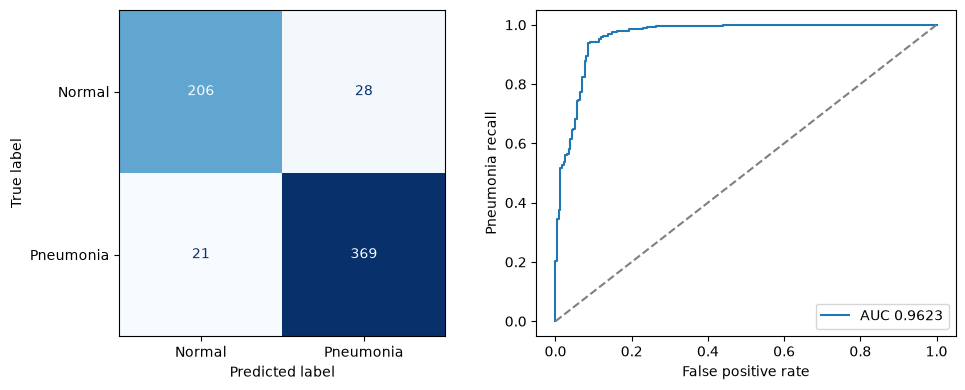

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay,roc_curve
fig,axs=plt.subplots(1,2,figsize=(10,4))
ConfusionMatrixDisplay(np.array(summary['metrics']['confusion_matrix']),display_labels=['Normal','Pneumonia']).plot(ax=axs[0],colorbar=False,cmap='Blues')
fpr,tpr,_=roc_curve(y,p.mean(0));axs[1].plot(fpr,tpr,label=f"AUC {summary['metrics']['auc']:.4f}")
axs[1].plot([0,1],[0,1],'--',color='gray');axs[1].set(xlabel='False positive rate',ylabel='Pneumonia recall');axs[1].legend();fig.tight_layout();fig.savefig(OUT/'confusion_and_roc.png',dpi=140);plt.show()


## Actual training histories

Each model completed exactly five epochs and1635 optimizer steps. Each epoch processes all5232 records once. These are training losses on freshly augmented images, not validation or test accuracy curves. Final epoch-five weights were fixed before test evaluation.

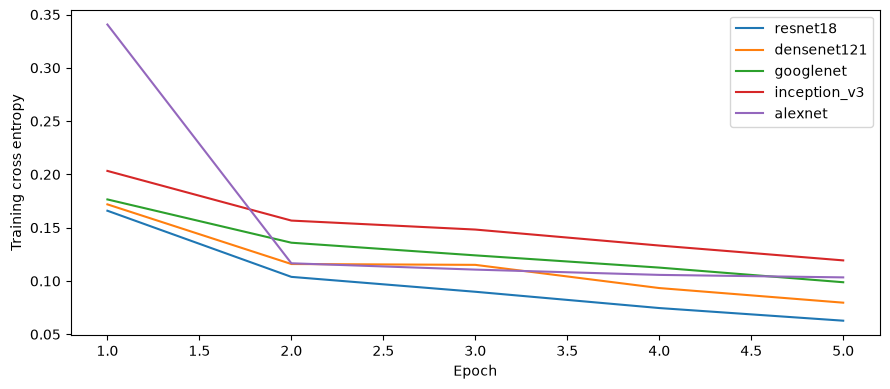

In [6]:
fig,ax=plt.subplots(figsize=(9,4))
for n in MODEL_NAMES:
    h=json.loads((OUT/f'{n}_history.json').read_text())
    assert len(h)==5 and all(a['training_records']==5232 for a in h)
    ax.plot([a['epoch'] for a in h],[a['training_loss'] for a in h],label=n)
ax.set(xlabel='Epoch',ylabel='Training cross entropy');ax.legend();fig.tight_layout();fig.savefig(OUT/'training_curves.png',dpi=140);plt.show()


# M3 lung cropping and CNN ViT proposal

## Revision before implementation

Revised5 October2026 before implementing either improvement. The proposed final system combines lung cropping and a pretrained small ViT with the five CNNs. Neither improvement has been implemented or measured. All three baseline experiments use full images and CNNs only. The corrected five-epoch experiment removes feature caching and restores the full paper-training partition. This revision supersedes the crop-only scope below, while retaining its crop mechanism, safeguards and numerical predictions.

The handout asks for one primary change. Cropping remains that primary hypothesis and the transformer is an explicit second extension. We will not describe their joint implementation as a one-variable experiment.

The final candidate is: a fixed lung segmenter supplies both lung masks; crop their union bounding box with10% margin before resizing original-resolution pixels to224; run the five CNNs and an ImageNet-pretrained DeiT-Tiny candidate; combine pneumonia probabilities. DeiT-Tiny is a resource-bounded choice, not an exact P9 DeiT-Base reproduction.

| Experiment | Input | Classifiers |
| --- | --- | --- |
| A | Full X-ray | Five CNNs, probability aggregation |
| B | Lung crop | Five CNNs, probability aggregation |
| C | Full X-ray | Five CNNs plus pretrained ViT |
| D | Lung crop | Five CNNs plus pretrained ViT |

B-A isolates cropping. C-A isolates adding ViT. D-B tests ViT on crops. D-C tests cropping in the hybrid. D is our final target, not the only comparison.

Use score=(1-w)*mean(CNN pneumonia probabilities)+w*ViT pneumonia probability. Predeclare w in{0,0.1,0.2,0.3,0.5} and thresholds in{0.4,0.5,0.6}. Select using validation macro F1 subject to the recall safeguard, then AUC, then lower ViT weight. For equal weight/AUC, prefer threshold0.5, then the lower threshold. The CNN-only comparator uses the same probability aggregation and validation threshold-selection process with w=0. Report the original P7 majority-vote reconstruction separately. Changing aggregation must not be mistaken for a ViT benefit.

Retain the crop prediction below for B-A. For adding ViT under a matched aggregation protocol, predict macro F1 +0.01 to +0.03 and accuracy +1 to +3 percentage points, with zero or negative gain possible. For D-A, predict macro F1 +0.01 to +0.04 and accuracy0 to +3 points with pneumonia recall no more than2 points lower. These are hypotheses, not measured gains, and are bounded by metric maxima. Crop and ViT gains must not be added together. No macro-F1 gain or a recall loss beyond2 points fails to support the combined hypothesis.

Keep the same deduplicated group split, source images, comparable per-model schedules, CNN trainable boundaries and augmentation across matched conditions. Choose checkpoints, weights and thresholds on validation only, never test. Filename groups remain proxies and the original benchmark test was previously inspected. Report class-specific metrics, paired uncertainty, crop failures and runtime. Begin ViT with a frozen-backbone classifier pilot and consider limited last-block tuning only after memory/time checks. One model at a time, two CPU threads and existing resource guards remain mandatory. No crop/ViT training starts before this M3 proposal is submitted.

CNN-transformer hybrids already exist. JEPA feature transfer and mixup remain optional later experiments, outside the primary four-way comparison. I-JEPA predicts image representations; V-JEPA focuses on video/world modelling. Mixup blends examples and labels and is not LeCun's JEPA method. None supplies new independent clinical evidence.

Sources: [DeiT](https://github.com/facebookresearch/deit), [existing hybrid](https://pmc.ncbi.nlm.nih.gov/articles/PMC10248870/), [I-JEPA](https://github.com/facebookresearch/ijepa), [mixup](https://arxiv.org/abs/1710.09412).

Recorded 5 October 2026. Status: proposed experiment, not implemented or measured.

## Selected baseline

P7: Chouhan et al., A Novel Transfer Learning Based Approach for Pneumonia Detection in Chest X-ray Images, Applied Sciences 10(2), 559, 2020. DOI: https://doi.org/10.3390/app10020559.

Five ImageNet-pretrained CNNs (AlexNet, DenseNet121, InceptionV3, ResNet18 and GoogLeNet) use frozen early feature layers and trainable late blocks/classifiers as specified by the paper's Figures4-8. Three or more pneumonia votes give the final label. Our local five-epoch schedule is a declared resource limit. This replaces the tentative Kermany/InceptionV3 baseline presented in M1 while retaining the change to image region.

## Primary crop hypothesis retained from the earlier proposal

Replace the full image with a lung-focused crop derived from a pretrained chest X-ray lung segmentation model. Use the union of both lung masks, expand its bounding box by a fixed 10% margin, then resize the crop to 224 by 224. Keep the same five classifiers, training schedule, augmentation, split, seed and majority-vote rule in the paired control and crop experiments.

For M4, obtain original-resolution pixels from the verified source shards again and crop BEFORE the initial 224-pixel resize. The current Mac cache contains only the M2 initial resize. Cropping that small cache and enlarging it would not recover lung detail. Process original images one shard at a time rather than storing the entire full-resolution collection. The paired full-image control will use those same source pixels and the same final resize.

Cropping is one input-preprocessing variable. In B versus A, keep the classifier family and aggregation identical. C and D separately introduce the transformer extension stated above. The segmentation model must be fixed and trained on separate data. Failed masks fall back to the full image, with the failure count reported. A crop is a bounding rectangle and can contain non-lung pixels. We do not claim that it removes all shortcuts.

The concrete candidate is TorchXRayVision's pretrained ChestX-Det PSPNet, whose official code exposes Left Lung and Right Lung channels: https://github.com/mlmed/torchxrayvision. Its documentation, source and segmentation demo have been inspected; its weights and crop experiment have not been run here. It outputs 14 anatomy channels at 512 pixels and comes from ChestX-Det, not Kermany. M4 will use its documented preprocessing, apply sigmoid to the output logits as in the official demo, and threshold the left/right lung probabilities at 0.5. Pediatric mask quality remains an explicit limitation.

## Hypothesis and mechanism

Lung-focused cropping may improve the balance between normal-class and pneumonia-class recognition by devoting more of the fixed input resolution to lung tissue and reducing peripheral image variation. It may also remove useful anatomy or fail on pediatric images, so improvement is uncertain.

## Numerical prediction before the experiment

Relative to an identically run full-image control, we predict **macro F1 increases by 0.01 to 0.03**, **normal-class recall (specificity) increases by 2 to 5 percentage points**, and **ROC AUC changes by 0.00 to +0.02**. We predict pneumonia recall changes within **minus 2 to plus 2 percentage points**, and accuracy within **minus 1 to plus 2 percentage points**. These are reasoned predictions, not results, confidence intervals or a claim of state of the art.

This updates M1's prediction of less than one percentage point accuracy movement: after changing the base paper, we make macro F1 and specificity the primary expected benefit. We retain the possibility of little or no accuracy improvement. No crop experiment has been run for M2/M3.

## M4 evaluation design

1. Use the fixed deduplicated group split from the audited restart or predeclare any justified replacement before the new runs. Document normal-image identifier ambiguity. Preserve the original624-image benchmark partition for paired final evaluation, but disclose it was inspected earlier and is not a blind external holdout. Also report unique-image sensitivity analysis. Do not tune on test scores.
2. Re-run the full-image control under that split. The M2 paper-comparison score is not interchangeable with this new protocol's control score.
3. Run A/B/C/D with matching settings and the probability-aggregation controls specified in the revision. Select checkpoints by validation macro F1, then AUC and earlier epoch. The original three-of-five vote remains a separately reported reconstruction, not the aggregation control for judging ViT. Select any proposed weights/thresholds using validation only, then evaluate all declared conditions on test.
4. Repeat paired runs for seeds 42, 43 and 44 if resources allow. Report the seed results and paired bootstrap intervals for metric differences. Do not infer significance from overlap of separate intervals.
5. Report accuracy, pneumonia sensitivity, specificity, precision, both class F1 scores, macro F1, AUC and confusion matrices. Include five to ten errors and segmentation failures.
6. Optional diagnostic ablation: apply the fixed crop at test time only to the full-image baseline. This is a distribution-shift test, not the main treatment. A peripheral-only stress test cannot by itself prove shortcut learning.

Grad-CAM examples can support qualitative discussion for individual CNNs. Heatmap overlap with a lung mask measures anatomical concentration, not correct lesion localization, clinical correctness or causal reasoning. There are no lesion annotations here.

## What would refute the prediction

No macro-F1 gain, substantially worse pneumonia recall, or a crop effect indistinguishable from zero across paired seeds would fail to support the hypothesis. We will report the measured outcome even if cropping hurts. The assignment explicitly allows a wrong prediction when reasoning and analysis are sound.

## Scope

This is a student research-reproduction project on a single-center pediatric benchmark. We make no clinical deployment claim and no novelty or state-of-the-art claim. M3 ends with this proposal and the report introduction. Implementation and ablations belong to M4 after submitting this hypothesis.


## Limits

Matching paper partition/architecture does not establish exact author equivalence. Fresh augmentation severity, normalization, BatchNorm policy and classifier details remain declared choices. Five epochs is intentionally truncated. Single-center pediatric images, uncertain patient identifiers, repeated test records and one seed limit generalization. We do not select models or thresholds from test scores, claim a new state of the art or use predictions as clinical diagnoses.